<a href="https://colab.research.google.com/github/zainaBanglekar/CSL701-Roll_No_-CS03_Machine-Learning-Lab/blob/main/Experiments%20and%20Mini-Project/ML_Experiment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Student Name :Zaina Mujaveed Banglekar

Batch :CS-1


Roll Number :CS03



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [1]:

# ==========================================
# Task 1: Import Libraries and Load Dataset
# ==========================================

# 1. Import essential libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# 2. Upload your own dataset file
from google.colab import files

uploaded = files.upload()

# 3. Load the selected CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

# 4. Display the first five rows
print("First five rows of the dataset:")
display(df.head())

# 5. Display dataset information
print("\nDataset Information:")
df.info()

# 6. Display dataset shape
print("\nDataset Shape (rows, columns):")
print(df.shape)

# 7. Display column names
print("\nColumn Names:")
print(df.columns.tolist())


Saving palmerpenguins_extended.csv to palmerpenguins_extended.csv
First five rows of the dataset:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,diet,life_stage,health_metrics,year
0,Adelie,Biscoe,53.4,17.8,219.0,5687.0,female,fish,adult,overweight,2021
1,Adelie,Biscoe,49.3,18.1,245.0,6811.0,female,fish,adult,overweight,2021
2,Adelie,Biscoe,55.7,16.6,226.0,5388.0,female,fish,adult,overweight,2021
3,Adelie,Biscoe,38.0,15.6,221.0,6262.0,female,fish,adult,overweight,2021
4,Adelie,Biscoe,60.7,17.9,177.0,4811.0,female,fish,juvenile,overweight,2021



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3430 entries, 0 to 3429
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            3430 non-null   object 
 1   island             3430 non-null   object 
 2   bill_length_mm     3430 non-null   float64
 3   bill_depth_mm      3430 non-null   float64
 4   flipper_length_mm  3430 non-null   float64
 5   body_mass_g        3430 non-null   float64
 6   sex                3430 non-null   object 
 7   diet               3430 non-null   object 
 8   life_stage         3430 non-null   object 
 9   health_metrics     3430 non-null   object 
 10  year               3430 non-null   int64  
dtypes: float64(4), int64(1), object(6)
memory usage: 294.9+ KB

Dataset Shape (rows, columns):
(3430, 11)

Column Names:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'diet', 'life_stage', 'he

# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [3]:
# ==========================================
# Task 2: Select Features and Target & Preprocess
# ==========================================

# 1. Check missing values
print("Missing values before preprocessing:")
print(df.isnull().sum())

# 2. Select features and target
# Adjusted to use correct column names: 'bill_length_mm' and 'bill_depth_mm'
features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

target = "species"

X = df[features].copy()
y = df[target].copy()

# 3. Handle missing values
# Replace missing feature values with the median
X = X.fillna(X.median())

# Remove rows where the target species is missing
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows]

# 4. Encode categorical target labels
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# 5. Display processed data
print("\nFirst five rows of selected features:")
display(X.head())

print("\nEncoded target values:")
print(y[:5])

print("\nSpecies label mapping:")
for index, species in enumerate(label_encoder.classes_):
    print(f"{species} = {index}")

# 6. Check final dimensions
print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values after preprocessing:")
print(X.isnull().sum())

Missing values before preprocessing:
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
diet                 0
life_stage           0
health_metrics       0
year                 0
dtype: int64

First five rows of selected features:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,53.4,17.8,219.0,5687.0
1,49.3,18.1,245.0,6811.0
2,55.7,16.6,226.0,5388.0
3,38.0,15.6,221.0,6262.0
4,60.7,17.9,177.0,4811.0



Encoded target values:
[0 0 0 0 0]

Species label mapping:
Adelie = 0
Chinstrap = 1
Gentoo = 2

Features shape: (3430, 4)
Target shape: (3430,)

Missing values after preprocessing:
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
dtype: int64


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [4]:

# ==========================================
# Task 3: Split the Data
# ==========================================

from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the shapes of the datasets
print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

# Display the number of training and testing samples
print("\nNumber of training samples:", len(X_train))
print("Number of testing samples:", len(X_test))


Training Features Shape: (2744, 4)
Testing Features Shape: (686, 4)
Training Target Shape: (2744,)
Testing Target Shape: (686,)

Number of training samples: 2744
Number of testing samples: 686


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [5]:

# ==========================================
# Task 4: Implement CART Classifier
# ==========================================

# 1. Import DecisionTreeClassifier
from sklearn.tree import DecisionTreeClassifier

# 2. Create the CART model using Gini criterion
cart_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

# 3. Train the model
cart_model.fit(X_train, y_train)

# 4. Make predictions on the test data
y_pred = cart_model.predict(X_test)

# 5. Display actual and predicted values
print("Actual Species Labels:")
print(y_test)

print("\nPredicted Species Labels:")
print(y_pred)

# 6. Display the first 10 predictions
print("\nFirst 10 Predictions:")
for i in range(min(10, len(y_test))):
    actual_species = label_encoder.inverse_transform([y_test[i]])[0]
    predicted_species = label_encoder.inverse_transform([y_pred[i]])[0]

    print(f"Actual: {actual_species}, Predicted: {predicted_species}")


Actual Species Labels:
[0 2 0 0 0 2 1 0 2 0 0 0 0 0 2 2 2 2 0 0 1 0 1 1 0 0 0 1 0 2 0 2 0 2 2 0 0
 0 0 0 0 1 2 0 0 0 0 0 1 2 0 2 0 1 0 1 2 2 1 1 0 0 2 0 0 1 0 1 0 0 2 0 0 2
 0 0 0 2 0 2 2 0 0 0 1 2 0 0 1 1 0 2 0 2 2 0 1 2 1 0 1 1 2 1 2 0 0 0 2 2 2
 1 0 0 2 2 2 0 0 1 2 2 0 0 0 0 0 2 0 1 1 0 2 2 1 0 0 2 0 0 2 0 2 1 0 0 2 2
 0 1 0 2 2 0 0 0 2 0 1 1 1 0 2 0 2 0 2 0 0 1 1 1 0 1 0 0 2 0 2 0 2 0 2 0 0
 1 1 0 0 0 1 1 1 2 2 0 0 0 1 1 2 0 0 0 2 0 2 2 2 0 2 0 2 1 1 0 1 1 2 2 1 0
 2 2 2 2 0 0 0 0 0 2 1 2 0 0 2 2 0 1 2 0 2 0 2 2 2 0 2 0 1 1 0 2 0 2 0 0 0
 0 2 0 2 2 2 0 1 0 1 2 2 2 1 2 0 0 2 2 0 0 2 2 1 2 2 1 2 1 0 0 2 1 0 0 2 0
 2 1 2 2 0 2 0 2 2 2 0 0 0 2 0 0 2 2 0 0 0 1 2 2 1 2 2 2 1 1 1 0 0 0 1 0 2
 0 1 0 2 0 0 2 0 0 0 2 0 0 1 0 0 2 0 0 0 0 1 1 2 0 0 2 2 0 2 0 0 0 1 2 2 0
 2 1 1 0 0 0 0 0 0 0 2 1 1 1 0 1 1 0 2 0 2 2 2 0 0 0 2 0 2 2 0 0 2 0 2 0 2
 2 0 2 1 0 1 0 2 2 1 0 2 0 2 1 0 2 0 2 2 2 1 2 0 2 1 2 2 2 0 2 0 0 2 0 0 2
 2 0 0 1 0 1 1 0 0 2 1 0 2 2 2 0 2 0 2 2 0 2 2 2 0 0 1 1 2 0 2 2 0 0 0 2 0
 2

# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

CART Model Accuracy: 45.19 %

Confusion Matrix:
[[155  64  93]
 [ 48  33  44]
 [ 76  51 122]]


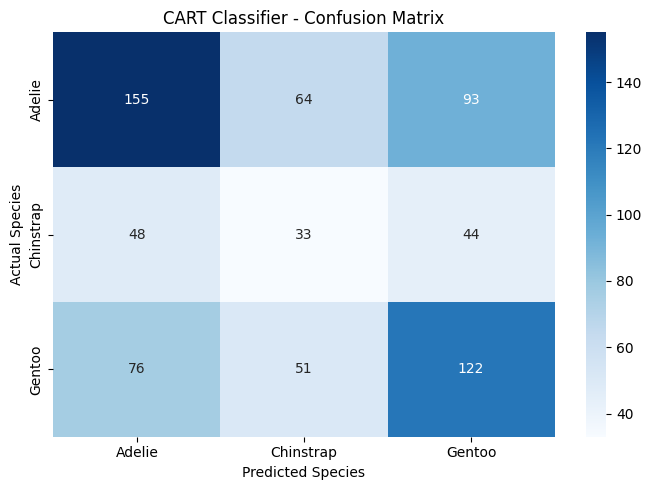


Classification Report:
              precision    recall  f1-score   support

      Adelie       0.56      0.50      0.52       312
   Chinstrap       0.22      0.26      0.24       125
      Gentoo       0.47      0.49      0.48       249

    accuracy                           0.45       686
   macro avg       0.42      0.42      0.42       686
weighted avg       0.46      0.45      0.46       686



In [6]:

# ==========================================
# Task 5: Evaluate CART Model
# ==========================================

# 1. Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("CART Model Accuracy:", round(accuracy * 100, 2), "%")

# 3. Generate Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# Visualize the confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("CART Classifier - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()

# 4. Generate Classification Report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=range(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)


# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


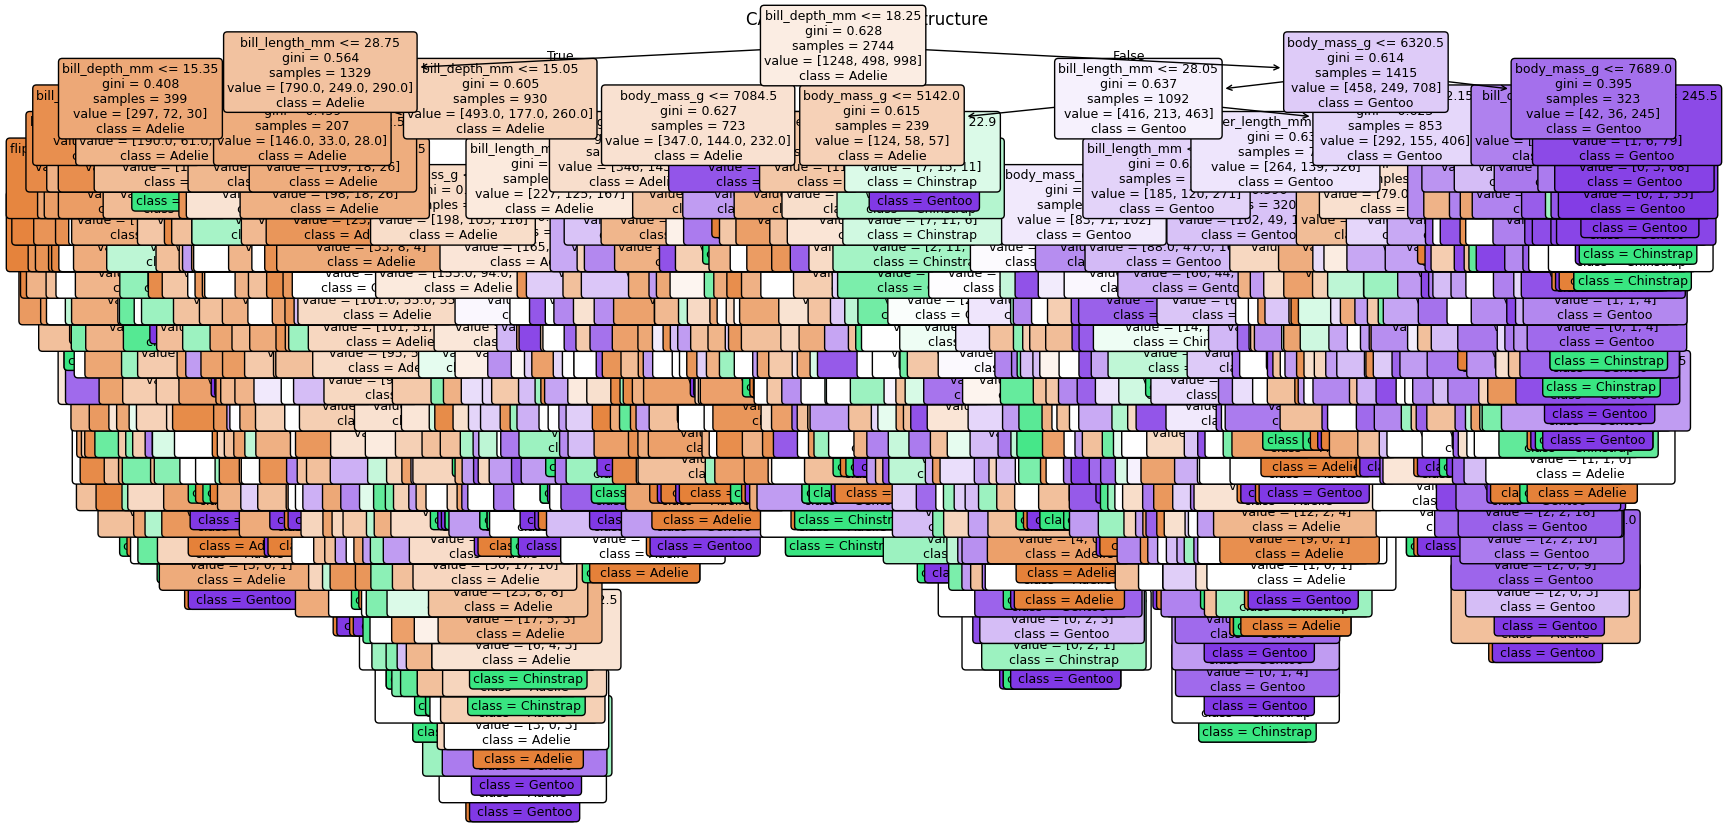

2D Decision Tree Accuracy: 43.88 %


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


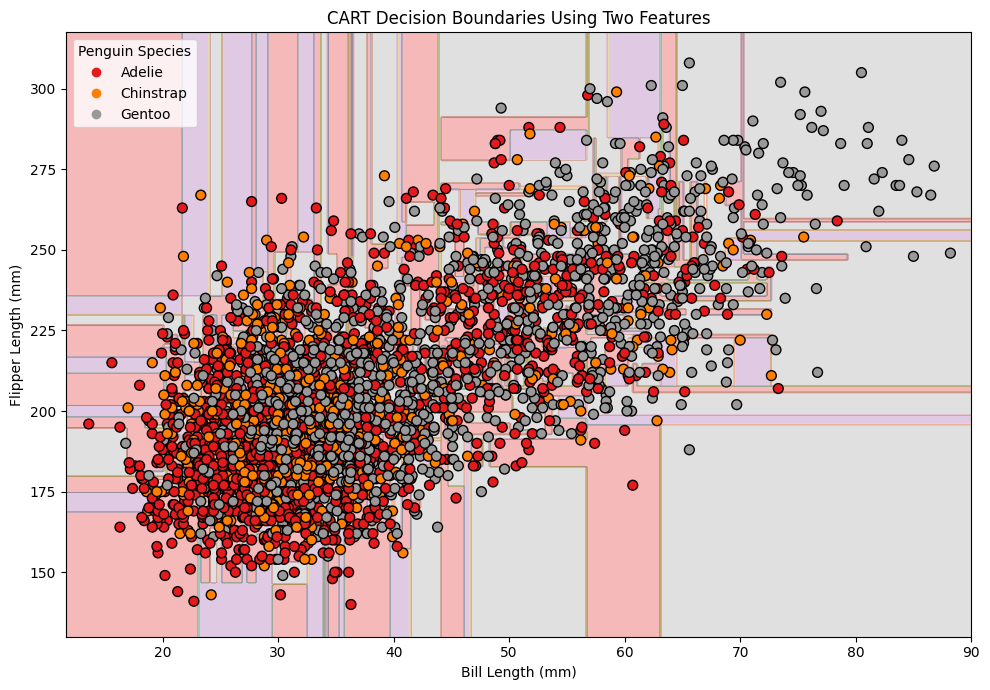

In [9]:
# ==========================================
# Task 6: Visualize Decision Tree & Decision Boundary
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree, DecisionTreeClassifier

# ------------------------------------------
# Part 1: Visualize the Full Decision Tree
# ------------------------------------------

plt.figure(figsize=(20, 10))

plot_tree(
    cart_model,
    feature_names=X.columns.tolist(),
    class_names=label_encoder.classes_.tolist(),
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("CART Decision Tree Structure")
plt.show()


# ------------------------------------------
# Part 2: Select Two Features
# ------------------------------------------

# Corrected 'culmen_length_mm' to 'bill_length_mm'
features_2d = ["bill_length_mm", "flipper_length_mm"]

X_2d = X[features_2d].copy()

# Split the 2D dataset
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# ------------------------------------------
# Part 3: Train the 2D Decision Tree
# ------------------------------------------

cart_2d = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

cart_2d.fit(X_train_2d, y_train_2d)

# Evaluate the 2D model
accuracy_2d = cart_2d.score(X_test_2d, y_test_2d)

print("2D Decision Tree Accuracy:",
      round(accuracy_2d * 100, 2), "%")


# ------------------------------------------
# Part 4: Plot Decision Boundaries
# ------------------------------------------

# Determine feature ranges
x_min, x_max = X_2d.iloc[:, 0].min() - 2, X_2d.iloc[:, 0].max() + 2
y_min, y_max = X_2d.iloc[:, 1].min() - 10, X_2d.iloc[:, 1].max() + 10

# Create a grid of points
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.2),
    np.arange(y_min, y_max, 0.5)
)

# Predict the class for every grid point
grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = cart_2d.predict(grid_points)
Z = Z.reshape(xx.shape)

# Plot rectangular decision regions
plt.figure(figsize=(10, 7))

plt.contourf(
    xx, yy, Z,
    alpha=0.3,
    cmap=plt.cm.Set1
)

# Plot the actual data points
scatter = plt.scatter(
    X_2d.iloc[:, 0],
    X_2d.iloc[:, 1],
    c=y,
    cmap=plt.cm.Set1,
    edgecolors="black",
    s=50
)

plt.xlabel("Bill Length (mm)")
plt.ylabel("Flipper Length (mm)")
plt.title("CART Decision Boundaries Using Two Features")

# Show species legend
handles, _ = scatter.legend_elements()
plt.legend(
    handles,
    label_encoder.classes_,
    title="Penguin Species"
)

plt.tight_layout()
plt.show()

# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

Logistic Regression Accuracy: 52.62 %


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


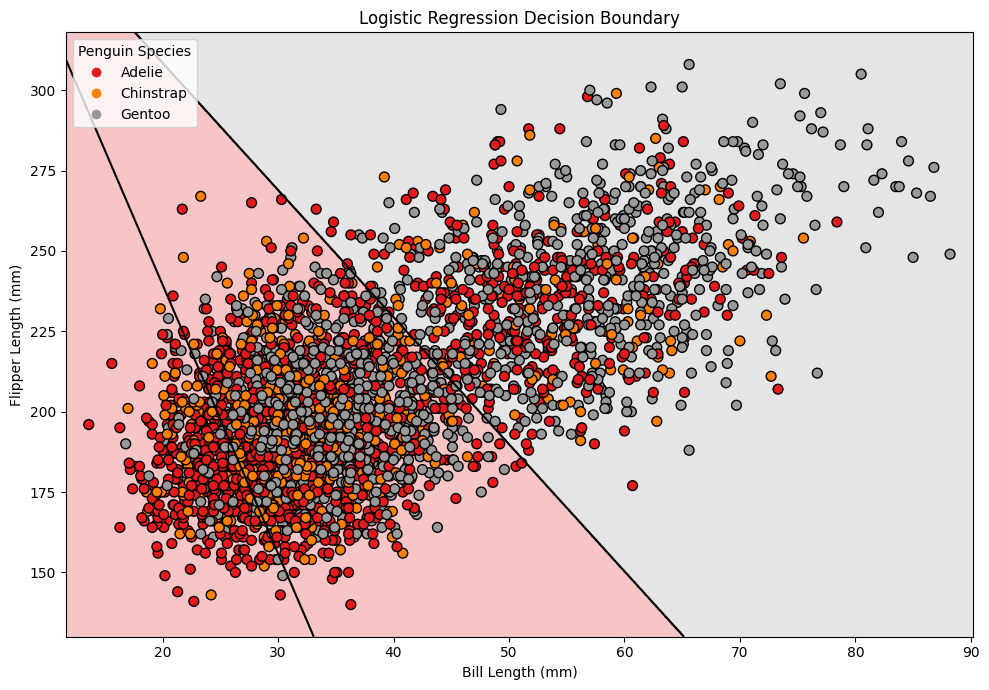

In [10]:

# ==========================================
# Task 7: Normal Linear Classification Boundary
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# ------------------------------------------
# 1. Select the same two features as Task 6
# ------------------------------------------

features_2d = ["bill_length_mm", "flipper_length_mm"]
X_2d = X[features_2d].copy()

# ------------------------------------------
# 2. Split the dataset
# ------------------------------------------

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# ------------------------------------------
# 3. Create and train Logistic Regression
# ------------------------------------------

logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

logistic_model.fit(X_train_2d, y_train_2d)

# ------------------------------------------
# 4. Evaluate the model
# ------------------------------------------

y_pred_logistic = logistic_model.predict(X_test_2d)

accuracy = accuracy_score(y_test_2d, y_pred_logistic)

print("Logistic Regression Accuracy:",
      round(accuracy * 100, 2), "%")

# ------------------------------------------
# 5. Create a grid for the decision boundary
# ------------------------------------------

x_min = X_2d["bill_length_mm"].min() - 2
x_max = X_2d["bill_length_mm"].max() + 2

y_min = X_2d["flipper_length_mm"].min() - 10
y_max = X_2d["flipper_length_mm"].max() + 10

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 400),
    np.linspace(y_min, y_max, 400)
)

grid_points = np.c_[xx.ravel(), yy.ravel()]

# Predict species for each grid point
Z = logistic_model.predict(grid_points).reshape(xx.shape)

# ------------------------------------------
# 6. Plot decision regions and data points
# ------------------------------------------

plt.figure(figsize=(10, 7))

plt.contourf(
    xx, yy, Z,
    alpha=0.25,
    cmap=plt.cm.Set1
)

# Plot the actual penguin samples
scatter = plt.scatter(
    X_2d["bill_length_mm"],
    X_2d["flipper_length_mm"],
    c=y,
    cmap=plt.cm.Set1,
    edgecolors="black",
    s=50
)

# Draw pairwise linear decision boundaries
probabilities = logistic_model.predict_proba(grid_points)

for i in range(probabilities.shape[1]):
    for j in range(i + 1, probabilities.shape[1]):
        boundary = (
            probabilities[:, i] - probabilities[:, j]
        ).reshape(xx.shape)

        plt.contour(
            xx, yy, boundary,
            levels=[0],
            colors="black",
            linewidths=1.5
        )

plt.xlabel("Bill Length (mm)")
plt.ylabel("Flipper Length (mm)")
plt.title("Logistic Regression Decision Boundary")

handles, _ = scatter.legend_elements()
plt.legend(
    handles,
    label_encoder.classes_,
    title="Penguin Species"
)

plt.tight_layout()
plt.show()


# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

CART Accuracy: 43.88 %
Logistic Regression Accuracy: 52.62 %


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


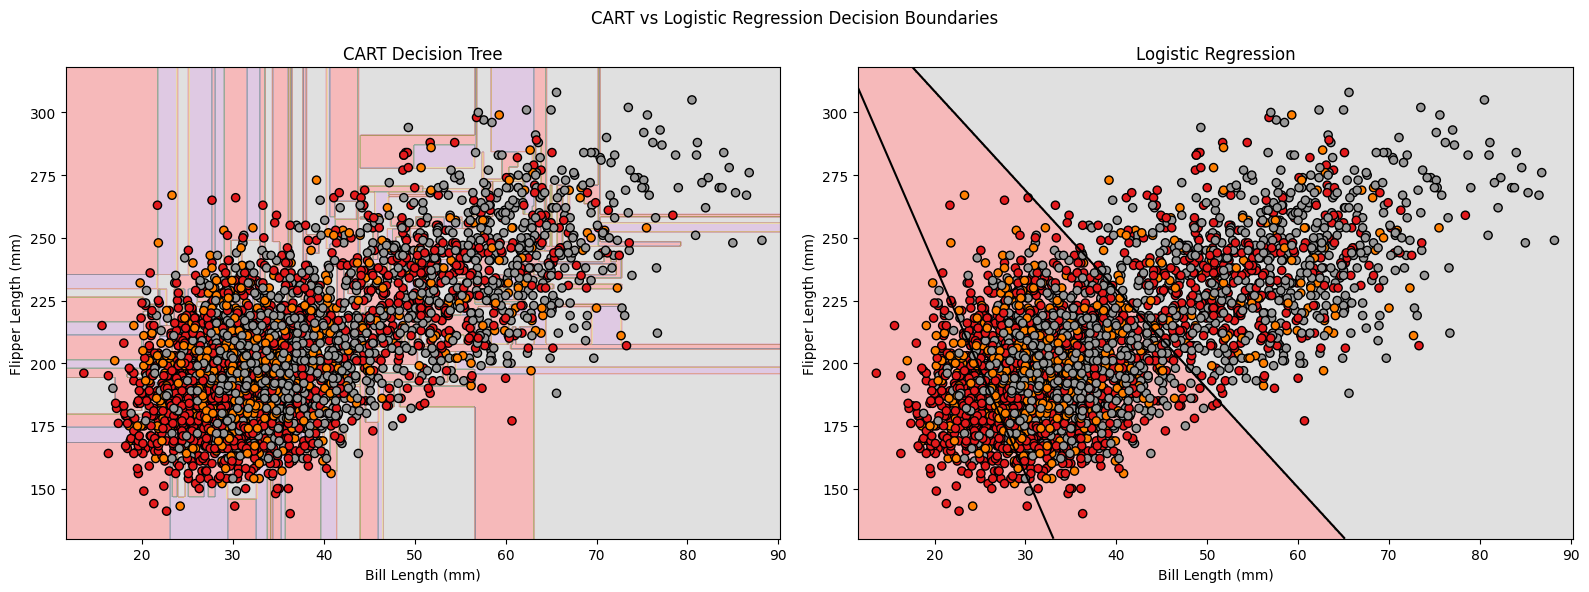

In [11]:

# ==========================================
# Task 8: Compare CART and Logistic Regression
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# ------------------------------------------
# 1. Select two features
# ------------------------------------------

features_2d = ["bill_length_mm", "flipper_length_mm"]
X_2d = X[features_2d].copy()

# ------------------------------------------
# 2. Split the data
# ------------------------------------------

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# ------------------------------------------
# 3. Train CART Decision Tree
# ------------------------------------------

cart_2d = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

cart_2d.fit(X_train_2d, y_train_2d)

# ------------------------------------------
# 4. Train Logistic Regression
# ------------------------------------------

logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

logistic_model.fit(X_train_2d, y_train_2d)

# ------------------------------------------
# 5. Evaluate both models
# ------------------------------------------

cart_pred = cart_2d.predict(X_test_2d)
logistic_pred = logistic_model.predict(X_test_2d)

print("CART Accuracy:",
      round(accuracy_score(y_test_2d, cart_pred) * 100, 2), "%")

print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test_2d, logistic_pred) * 100, 2), "%")

# ------------------------------------------
# 6. Create a grid for decision boundaries
# ------------------------------------------

x_min = X_2d["bill_length_mm"].min() - 2
x_max = X_2d["bill_length_mm"].max() + 2

y_min = X_2d["flipper_length_mm"].min() - 10
y_max = X_2d["flipper_length_mm"].max() + 10

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 400),
    np.linspace(y_min, y_max, 400)
)

grid_points = np.c_[xx.ravel(), yy.ravel()]

# Predict regions for each model
Z_cart = cart_2d.predict(grid_points).reshape(xx.shape)
Z_logistic = logistic_model.predict(grid_points).reshape(xx.shape)

# ------------------------------------------
# 7. Plot side-by-side decision boundaries
# ------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# CART Decision Tree
axes[0].contourf(
    xx, yy, Z_cart,
    alpha=0.3,
    cmap=plt.cm.Set1
)

axes[0].scatter(
    X_2d["bill_length_mm"],
    X_2d["flipper_length_mm"],
    c=y,
    cmap=plt.cm.Set1,
    edgecolors="black",
    s=35
)

axes[0].set_title("CART Decision Tree")
axes[0].set_xlabel("Bill Length (mm)")
axes[0].set_ylabel("Flipper Length (mm)")

# Logistic Regression
axes[1].contourf(
    xx, yy, Z_logistic,
    alpha=0.3,
    cmap=plt.cm.Set1
)

axes[1].scatter(
    X_2d["bill_length_mm"],
    X_2d["flipper_length_mm"],
    c=y,
    cmap=plt.cm.Set1,
    edgecolors="black",
    s=35
)

# Add pairwise linear boundaries for Logistic Regression
probabilities = logistic_model.predict_proba(grid_points)

for i in range(probabilities.shape[1]):
    for j in range(i + 1, probabilities.shape[1]):
        boundary = (
            probabilities[:, i] - probabilities[:, j]
        ).reshape(xx.shape)

        axes[1].contour(
            xx, yy, boundary,
            levels=[0],
            colors="black",
            linewidths=1.5
        )

axes[1].set_title("Logistic Regression")
axes[1].set_xlabel("Bill Length (mm)")
axes[1].set_ylabel("Flipper Length (mm)")

plt.suptitle("CART vs Logistic Regression Decision Boundaries")
plt.tight_layout()
plt.show()


# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

========== MODEL ACCURACY ==========
CART Decision Tree: 43.88%
Logistic Regression: 52.62%


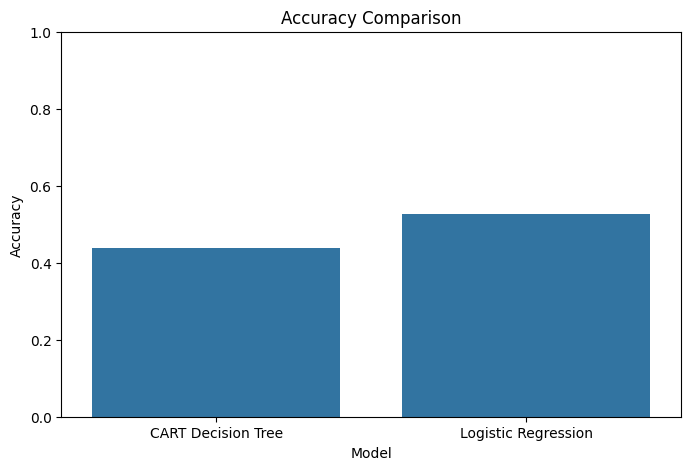

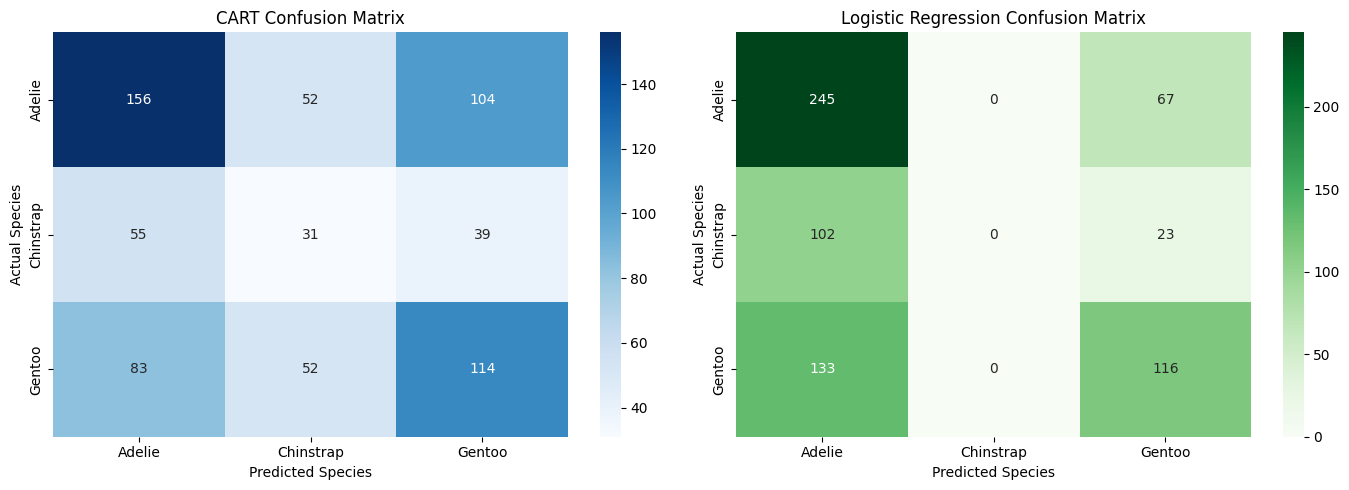


========== CART CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

      Adelie       0.53      0.50      0.51       312
   Chinstrap       0.23      0.25      0.24       125
      Gentoo       0.44      0.46      0.45       249

    accuracy                           0.44       686
   macro avg       0.40      0.40      0.40       686
weighted avg       0.44      0.44      0.44       686


===== LOGISTIC REGRESSION CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

      Adelie       0.51      0.79      0.62       312
   Chinstrap       0.00      0.00      0.00       125
      Gentoo       0.56      0.47      0.51       249

    accuracy                           0.53       686
   macro avg       0.36      0.42      0.38       686
weighted avg       0.44      0.53      0.47       686


========== PERFORMANCE COMPARISON ==========


,CART,Logistic Regression
Accuracy,0.4388,0.5262
Precision (macro avg),0.4013,0.3578
Recall (macro avg),0.4019,0.4170
F1-score (macro avg),0.4013,0.3762


In [12]:

# ==========================================
# Task 9: Compare Performance
# CART vs Logistic Regression
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------
# 1. Make predictions using both models
# ------------------------------------------

# CART predictions
y_pred_cart = cart_2d.predict(X_test_2d)

# Logistic Regression predictions
y_pred_logistic = logistic_model.predict(X_test_2d)

# ------------------------------------------
# 2. Calculate accuracy
# ------------------------------------------

cart_accuracy = accuracy_score(y_test_2d, y_pred_cart)
logistic_accuracy = accuracy_score(y_test_2d, y_pred_logistic)

print("========== MODEL ACCURACY ==========")
print(f"CART Decision Tree: {cart_accuracy * 100:.2f}%")
print(f"Logistic Regression: {logistic_accuracy * 100:.2f}%")

# Compare accuracy using a bar chart
accuracy_df = pd.DataFrame({
    "Model": ["CART Decision Tree", "Logistic Regression"],
    "Accuracy": [cart_accuracy, logistic_accuracy]
})

plt.figure(figsize=(8, 5))
sns.barplot(data=accuracy_df, x="Model", y="Accuracy")
plt.ylim(0, 1)
plt.title("Accuracy Comparison")
plt.ylabel("Accuracy")
plt.show()

# ------------------------------------------
# 3. Confusion matrices
# ------------------------------------------

class_labels = list(range(len(label_encoder.classes_)))
species_names = label_encoder.classes_

cm_cart = confusion_matrix(
    y_test_2d, y_pred_cart, labels=class_labels
)

cm_logistic = confusion_matrix(
    y_test_2d, y_pred_logistic, labels=class_labels
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    cm_cart,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=species_names,
    yticklabels=species_names,
    ax=axes[0]
)
axes[0].set_title("CART Confusion Matrix")
axes[0].set_xlabel("Predicted Species")
axes[0].set_ylabel("Actual Species")

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=species_names,
    yticklabels=species_names,
    ax=axes[1]
)
axes[1].set_title("Logistic Regression Confusion Matrix")
axes[1].set_xlabel("Predicted Species")
axes[1].set_ylabel("Actual Species")

plt.tight_layout()
plt.show()

# ------------------------------------------
# 4. Classification reports
# ------------------------------------------

print("\n========== CART CLASSIFICATION REPORT ==========")
print(classification_report(
    y_test_2d,
    y_pred_cart,
    labels=class_labels,
    target_names=species_names,
    zero_division=0
))

print("\n===== LOGISTIC REGRESSION CLASSIFICATION REPORT =====")
print(classification_report(
    y_test_2d,
    y_pred_logistic,
    labels=class_labels,
    target_names=species_names,
    zero_division=0
))

# ------------------------------------------
# 5. Compare precision, recall and F1-score
# ------------------------------------------

cart_report = classification_report(
    y_test_2d,
    y_pred_cart,
    labels=class_labels,
    target_names=species_names,
    output_dict=True,
    zero_division=0
)

logistic_report = classification_report(
    y_test_2d,
    y_pred_logistic,
    labels=class_labels,
    target_names=species_names,
    output_dict=True,
    zero_division=0
)

comparison = pd.DataFrame({
    "CART": {
        "Accuracy": cart_accuracy,
        "Precision (macro avg)": cart_report["macro avg"]["precision"],
        "Recall (macro avg)": cart_report["macro avg"]["recall"],
        "F1-score (macro avg)": cart_report["macro avg"]["f1-score"]
    },
    "Logistic Regression": {
        "Accuracy": logistic_accuracy,
        "Precision (macro avg)": logistic_report["macro avg"]["precision"],
        "Recall (macro avg)": logistic_report["macro avg"]["recall"],
        "F1-score (macro avg)": logistic_report["macro avg"]["f1-score"]
    }
})

print("\n========== PERFORMANCE COMPARISON ==========")
display(comparison.round(4))


# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.